# Safewater Lines · Your Voice: analysis to organisational action

**Purpose:** explain what employees experience, what Safewater Lines should preserve, and where practical improvements are needed. The final output will be an executive PowerPoint with evidence, priorities, proposed owners, and success measures; it follows the completed analysis.

**One working notebook.** Part A (§1–12) prepares and explores the data. Part B starts **after the EDA summary** with Step 1: analytical foundation, research, and method selection. Later analysis belongs here before the annexure. The final Markdown cell is the methodology reference table.

Source: `data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx`, responses as of 21 Oct. Assignment deadline: **30 October 2026, TISS premises**. Organisation brief: [project brief](../docs/PROJECT_BRIEF.md). Decisions: [project brain](../docs/PROJECT_BRAIN.md).

Part A results are exploratory. Step 1 establishes how we can responsibly use them; relationships are not causal effects, and no official external survey certification is assumed.

In [1]:
from pathlib import Path
import re
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx"
OUT = ROOT / "data/processed"

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

BLUE = "#2a78d6"
LIKERT_COLORS = ["#c63d2f", "#ec9a8a", "#dddcd8", "#8fb8ea", "#2a78d6"]   # 1 → 5, diverging around grey

## 1. Workbook inventory

In [2]:
xl = pd.ExcelFile(RAW)
pd.DataFrame(
    [(s, *pd.read_excel(xl, s, header=None).shape) for s in xl.sheet_names],
    columns=["sheet", "rows", "cols"],
)

,sheet,rows,cols
0,Sheet2,15,3
1,SWL - MASTERDATA,329,43
2,Masterdata - do not refer,330,43
3,English,270,43
4,Hindi,26,43
5,Marathi,31,43
6,Tamil,6,43
7,Malayalam,2,43


| Sheet | Use |
|---|---|
| `SWL - MASTERDATA` | Supplied consolidated master; use for analysis |
| `Masterdata - do not refer` | Excluded older copy |
| English, Hindi, Marathi, Tamil, Malayalam | Original language exports; use only for source checks |
| `Sheet2` | HR-priority pivot and option-to-theme mapping |

Language exports contain 330 rows; the master contains 327 responses. The difference is **not an audited deletion log**: do not claim that exactly three test responses were removed without reconciling records. The master also fixes tenure values that became dates in the language sheets.

In [3]:
pd.read_excel(xl, "English", header=None).iloc[1:, 3].astype(str).value_counts().head(8)

3
0 - 3                  104
15 & Above              47
2026-05-03 00:00:00     44
2026-10-05 00:00:00     42
2015-10-01 00:00:00     32
Name: count, dtype: int64

In the raw language sheets, Excel **auto-converted the tenure bands into dates**
(`5 - 10` → 2026-10-05, `3 - 5` → 2026-05-03, `10 - 15` → 2015-10-01, `46300` = a date serial).
The master has them fixed. **Never analyse the raw sheets directly.**

In [4]:
pd.read_excel(xl, "Sheet2", header=2).dropna(how="all", axis=1).dropna(how="all")

,Row Labels,Count of What is one thing you would like HR to do better?,Unnamed: 2
0,Being available and easy to approach,18.0,Approachable
1,Employee activities and engagement,13.0,Engagement
2,Help employees progress in their careers,51.0,Development
3,Help resolve employee problems,35.0,Grievances
4,Improve employee benefits and facilities,51.0,Benefits & Facilities
5,Keeping employees informed,13.0,Communication
6,Listening to employees and their concerns,67.0,Communication
7,Making rules and processes simple,20.0,Process & Policies
8,Recognising and appreciating good work,31.0,R&R
9,Supporting employees when they need help,29.0,Grievances


`Sheet2` maps 10 HR-priority options to **eight themes**. Its pivot totals 328, while the analysis master has 327 responses. Reuse the option mapping, but recompute all counts from the master in §10.

## 2. Load the master and build a codebook
The header spans two rows: row 1 = dimension (merged cells), row 2 = question text.

In [5]:
hdr = pd.read_excel(xl, "SWL - MASTERDATA", header=None, nrows=2)
hdr.T.head(8)

,0,1
0,NaN,Your Workplace Location
1,NaN,Do not want to disclose
2,NaN,Your Current Department
3,NaN,Your years of Service
4,NaN,Gender
5,NaN,Your Full name - This is optional
6,CREDIBILITY,Communication from senior leadership is open and honest.
7,NaN,Our leaders do what they say they will do.


In [6]:
dims = hdr.iloc[0].ffill()
questions = hdr.iloc[1]
questions.iloc[1]

'Do not want to disclose'

Column 2's header says *"Do not want to disclose"*: a header cell got overwritten by a response value.
The `do not refer` sheet shows the real name: **Your Current Designation**.

In [7]:
DIM_CODE = {"CREDIBILITY": "CRE", "RESPECT": "RES", "FAIRNESS": "FAI", "PRIDE": "PRI",
            "CAMARADERIE": "CAM", "OVERALL EMPLOYEE EXPERIENCE": "OVR"}
demo_names = ["location", "designation", "department", "tenure", "gender", "full_name"]
oe_names = ["oe_leaders_trust", "oe_feel_valued", "oe_fairness_concern",
            "oe_value_most", "oe_teamwork", "oe_one_change"]

item_names = [f"{DIM_CODE[d]}{i % 5 + 1}" for i, d in enumerate(dims.iloc[6:36])]
cols = demo_names + item_names + oe_names + ["hr_priority"]
len(cols), item_names[:6]

(43, ['CRE1', 'CRE2', 'CRE3', 'CRE4', 'CRE5', 'RES1'])

In [8]:
codebook = pd.DataFrame({
    "col": cols,
    "block": ["demographic"] * 6 + list(dims.iloc[6:36]) + ["open-ended"] * 6 + ["single-choice"],
    "question": ["Your Current Designation" if i == 1 else q for i, q in enumerate(questions)],
})
codebook

,col,block,question
0,location,demographic,Your Workplace Location
1,designation,demographic,Your Current Designation
2,department,demographic,Your Current Department
3,tenure,demographic,Your years of Service
4,gender,demographic,Gender
5,full_name,demographic,Your Full name - This is optional
6,CRE1,CREDIBILITY,Communication from senior leadership is open and honest.
7,CRE2,CREDIBILITY,Our leaders do what they say they will do.
8,CRE3,CREDIBILITY,I have confidence in the direction of the organization.
9,CRE4,CREDIBILITY,Senior leaders communicate important changes in a timely manner


In [9]:
raw = pd.read_excel(xl, "SWL - MASTERDATA", header=None, skiprows=2, names=cols)
raw.shape

(327, 43)

In [10]:
ITEMS = item_names
DIMS = list(DIM_CODE.values())
OE = oe_names
DEMO = ["location", "designation", "department", "tenure", "gender"]

## 3. Data quality

In [11]:
quality = pd.DataFrame({
    "valid_n": raw.notna().sum(),
    "missing_n": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100),
})
display(quality.loc[quality["missing_n"] > 0].round(1))
display(pd.Series({
    "respondents": len(raw),
    "rating_items": len(ITEMS),
    "missing_rating_cells": int(raw[ITEMS].isna().sum().sum()),
    "name_supplied_pct": round(raw["full_name"].notna().mean() * 100, 1),
    "duplicate_rows_excluding_name": int(raw.drop(columns="full_name").duplicated().sum()),
}, name="base_checks"))

,valid_n,missing_n,missing_pct
full_name,227,100,30.6
oe_leaders_trust,318,9,2.8
oe_feel_valued,316,11,3.4
oe_fairness_concern,308,19,5.8
oe_value_most,318,9,2.8
oe_teamwork,317,10,3.1
oe_one_change,315,12,3.7


respondents                      327.0
rating_items                      30.0
missing_rating_cells               0.0
name_supplied_pct                 69.4
duplicate_rows_excluding_name      0.0
Name: base_checks, dtype: float64

All demographic fields and rating items are complete in the supplied master; completeness alone does not establish that the form forced responses. Names were supplied by about 69% of respondents, so those records are identifiable in the source. We remove names from processed data. Possible effects on answering remain an interpretation question, not a demonstrated cause of high scores.

### Likert labels

In [12]:
pd.Series(raw[ITEMS].values.ravel()).value_counts()

Almost always    3991
Usually          2358
Almost Always    1779
Sometimes         981
Rarely            359
Often             173
Almost Never      118
Always             30
Almost never       21
Name: count, dtype: int64

There are 9 labels for a 5-point scale:
- case variants: `Almost always` / `Almost Always`, `Almost never` / `Almost Never`
- `Often` (173) only comes from the **Hindi** form, which used *Often* where the others used *Usually*
- `Always` (30) is the single **Malayalam** respondent, who picked the top option on every question

Mapping: Almost never 1 · Rarely 2 · Sometimes 3 · Usually / Often 4 · Almost always / Always 5

In [13]:
SCALE = {"almost never": 1, "rarely": 2, "sometimes": 3, "usually": 4, "often": 4,
         "almost always": 5, "always": 5}
raw[ITEMS].apply(lambda c: c.str.strip().str.lower().map(SCALE)).isna().sum().sum()

np.int64(0)

### Response-style checks

In [14]:
L = raw[ITEMS].apply(lambda c: c.str.strip().str.lower().map(SCALE))
straight = L.nunique(axis=1).eq(1)
straight.sum(), L.loc[straight, "CRE1"].value_counts().to_dict()

(np.int64(54), {5: 51, 4: 2, 3: 1})

54 respondents (16.5%) chose the same category on all 30 items; 51 chose 5 throughout. This could reflect genuinely consistent views or a response style. Without further evidence we cannot identify careless responses. Retain everyone in the main analysis and use an explicitly labelled exclusion only as a sensitivity check (§9).

### Category hygiene

Designation is free text, with case variants and some ambiguous entries. The keyword-based level grouping below is an **analyst-created approximation**, not a verified organisational hierarchy. Keep `Unclear` separate and do not interpret the numeric prefixes as measured distances or validated seniority ranks.

In [15]:
raw["department"].value_counts()

department
Documentation                   59
Sales                           54
Customer Service                51
Finance & Accounts              38
Operations                      36
Customs Clearance               13
Accounts - Trade                11
Pricing                          9
Business Development             8
Billing                          8
Administration                   7
Credit Control                   5
BPO                              5
AMS                              4
Human Resources                  3
Commercial                       2
Marketing                        2
Sales Support                    2
Information Technology           2
Inside Sales                     2
Do not want to disclose          1
FTWZ                             1
DISPATCH                         1
Product / System Development     1
BL release                       1
TRANSPORT & LOGISTICS            1
Name: count, dtype: int64

In [16]:
raw["location"].value_counts()

location
Mumbai         132
Noida           43
Cochin          33
Chennai         24
Kolkata         24
Ahmedabad       12
Hyderabad       11
Nhava Sheva     11
Gandhidham       7
Pune             5
Nairobi          4
Panipat          4
Kanpur           3
Ludhiana         2
Jaipur           2
Bangalore        2
Baroda           2
Coimbatore       1
New Jersey       1
Vizag            1
Tuticorin        1
Mundra           1
Aurangabad       1
Name: count, dtype: int64

## 4. Clean → analysis table `df`

In [17]:
def level(d: str) -> str:
    d = d.strip().lower()
    if any(k in d for k in ["chief", "general manager", "head of"]):
        return "6 Sr Leadership"
    if "assistant manager" in d or "team leader" in d or "supervisor" in d:
        return "4 AM / TL"
    if "manager" in d:
        return "5 Manager+"
    if "senior executive" in d:
        return "3 Sr Executive"
    if "executive" in d:
        return "2 Executive"
    if any(k in d for k in ["junior", "assistant", "runner", "off role"]):
        return "1 Junior / Support"
    return "0 Unclear"

REGION = {
    "West": ["Mumbai", "Nhava Sheva", "Pune", "Ahmedabad", "Gandhidham", "Baroda", "Mundra", "Aurangabad"],
    "North": ["Noida", "Kanpur", "Ludhiana", "Jaipur", "Panipat"],
    "South": ["Cochin", "Chennai", "Hyderabad", "Bangalore", "Coimbatore", "Vizag", "Tuticorin"],
    "East": ["Kolkata"],
    "Overseas": ["Nairobi", "New Jersey"],
}
CITY2REGION = {c: r for r, cs in REGION.items() for c in cs}
TENURE = ["0 - 3", "3 - 5", "5 - 10", "10 - 15", "15 & Above"]

In [18]:
df = raw.drop(columns="full_name").copy()
df[ITEMS] = L
df["level"] = df["designation"].map(level)
df["region"] = df["location"].map(CITY2REGION)
top_dept = df["department"].value_counts().loc[lambda s: s >= 10].index
df["dept_group"] = df["department"].where(df["department"].isin(top_dept), "Other")
df["tenure"] = pd.Categorical(df["tenure"], TENURE, ordered=True)
df["straightliner"] = straight
df["gave_name"] = raw["full_name"].notna()

In [19]:
df["region"].isna().sum(), df["level"].value_counts().sort_index()

(np.int64(0),
 level
 0 Unclear              12
 1 Junior / Support      9
 2 Executive           131
 3 Sr Executive         63
 4 AM / TL              51
 5 Manager+             51
 6 Sr Leadership        10
 Name: count, dtype: int64)

In [20]:
df.loc[df["level"] == "0 Unclear", "designation"].value_counts()

designation
Business Development        2
Trade -Africa               1
Do not want to disclose     1
Agency Network & CSM        1
Sales & operation           1
SALES                       1
Deputy Branch Accountant    1
BRANCH ACCOUNTANT           1
Branch Accountant           1
IMPORT                      1
Import export               1
Name: count, dtype: int64

### Working scores and denominators

- **Item favourable %:** number selecting 4 or 5 divided by valid answers to that item, ×100. It is a reporting convention here, not a validated engagement threshold. Category 3 means *Sometimes*, not *neutral*.
- **Dimension mean:** mean of the five specified items per respondent, then mean across respondents. Equal category spacing and equal item weights are explicit working assumptions; retain the response distributions alongside it.
- **Culture summary (`CULTURE_MEAN`):** equal-weight mean of the 25 items in CRE, RES, FAI, PRI and CAM. This is a descriptive project measure, **not an official culture summary or validated engagement scale**. OVR is excluded; PRI3 is included, so never correlate this composite with PRI3 as evidence of a driver.
- **`fav_pct`:** each respondent's share of favourable answers across all 30 items. This has a different scope from the 25-item culture summary. With complete, equally weighted items, its respondent average equals pooled item favourability.

Step 1 documents why these choices fit the questions and where other methods remain conditional.

In [21]:
for d in DIMS:
    df[d] = df[[f"{d}{i}" for i in range(1, 6)]].mean(axis=1)
TI_ITEMS = [c for c in ITEMS if not c.startswith("OVR")]
df["CULTURE_MEAN"] = df[TI_ITEMS].mean(axis=1)
df["fav_pct"] = (df[ITEMS] >= 4).mean(axis=1) * 100

## 5. Who answered?

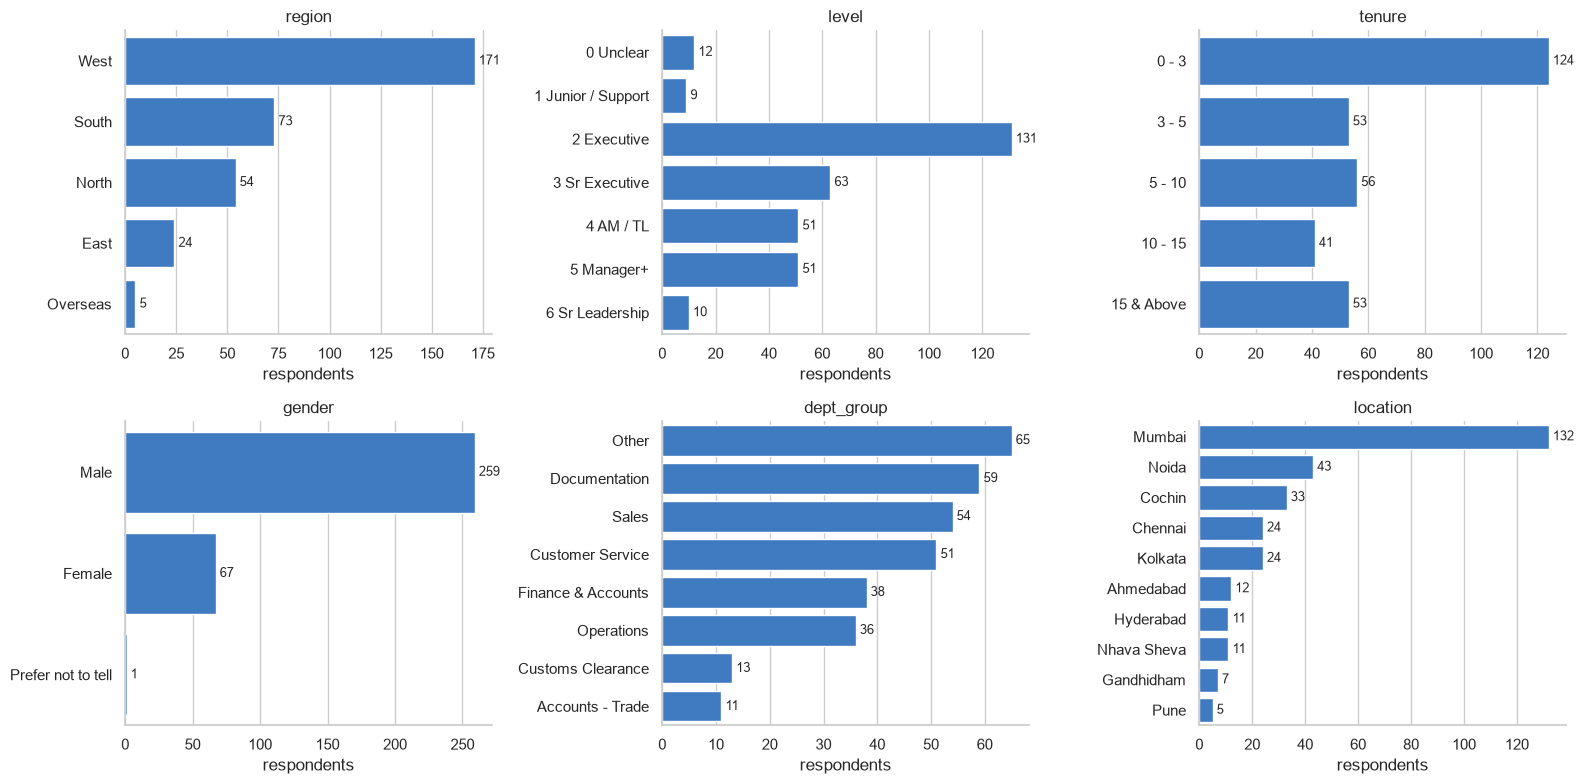

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["region", "level", "tenure", "gender", "dept_group", "location"]):
    vc = df[col].value_counts(sort=col not in ["tenure", "level"]).sort_index() if col in ["tenure", "level"] \
        else df[col].value_counts().head(10)
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color=BLUE)
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)
    ax.set(title=col, xlabel="respondents", ylabel="")
plt.tight_layout()

Mumbai and shorter-tenure employees form large shares of the respondent pool. These are **respondent composition**, not workforce composition: eligible employee counts were not provided. Always show group sizes. For presentation, use a provisional minimum group size of 10 and review possible identification; this is a project reporting rule, not a guarantee of anonymity or statistical adequacy.

## 6. Likert items

In [23]:
dist = (df[ITEMS].apply(lambda c: c.value_counts(normalize=True)).T.reindex(columns=[1, 2, 3, 4, 5]).fillna(0) * 100)
dist.index = [f"{c}  {q[:60]}" for c, q in zip(ITEMS, codebook.set_index("col").loc[ITEMS, "question"])]
dist = dist.iloc[::-1]

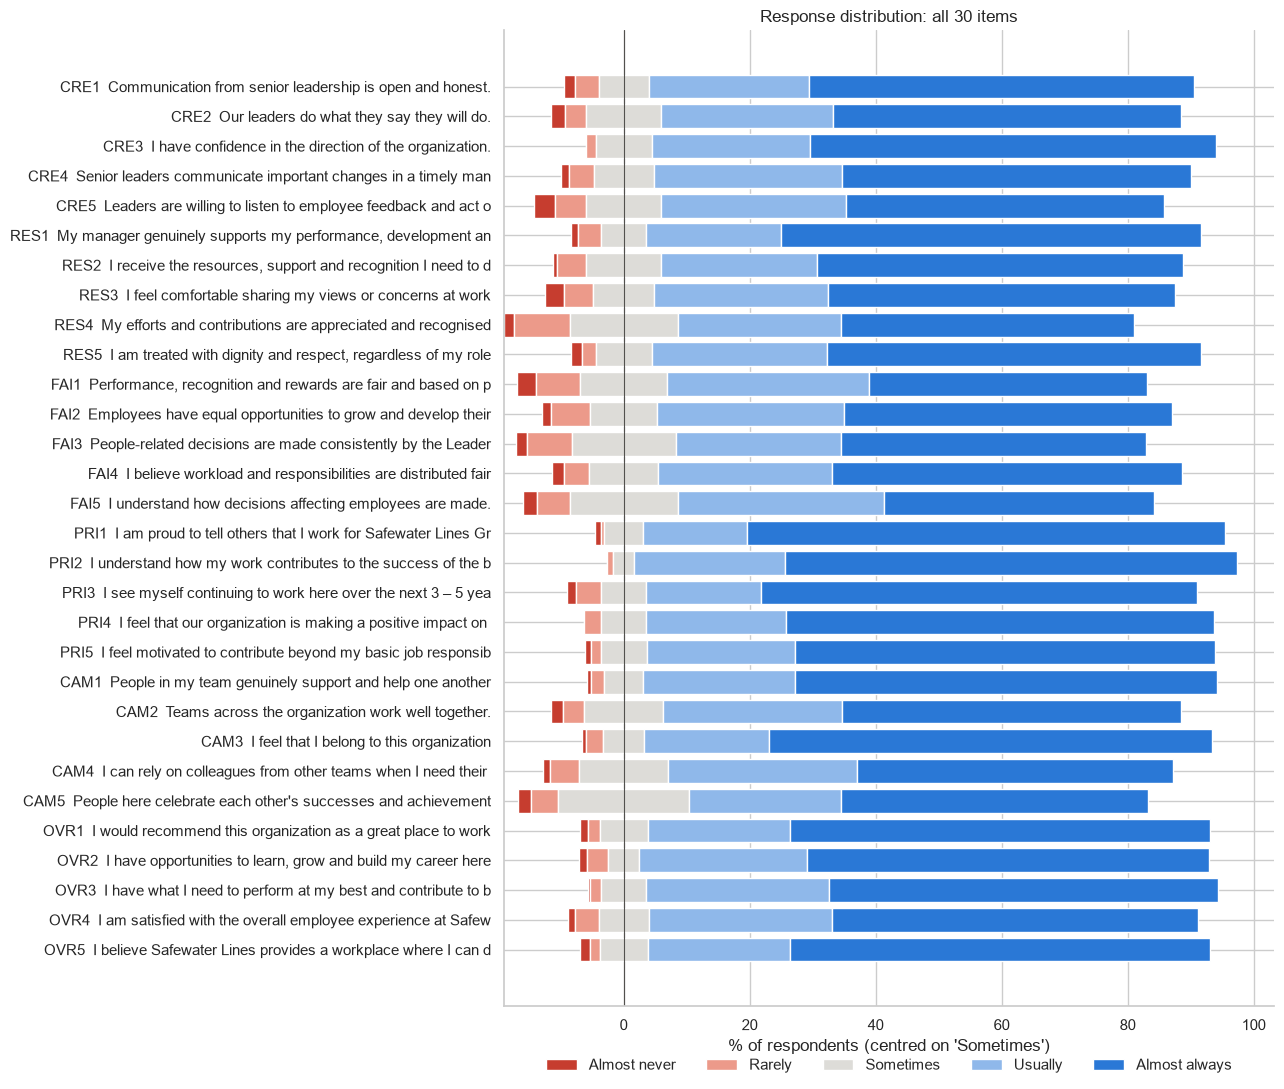

In [24]:
fig, ax = plt.subplots(figsize=(13, 11))
left = -(dist[1] + dist[2] + dist[3] / 2)
for k, color in zip([1, 2, 3, 4, 5], LIKERT_COLORS):
    ax.barh(dist.index, dist[k], left=left, color=color, edgecolor="white", linewidth=1,
            label=["Almost never", "Rarely", "Sometimes", "Usually", "Almost always"][k - 1])
    left = left + dist[k]
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(xlabel="% of respondents (centred on 'Sometimes')", title="Response distribution: all 30 items")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.04), frameon=False)
plt.tight_layout()

In [25]:
# Keep full precision for calculations and sorting; round only for display.
item_counts = pd.DataFrame({k: df[ITEMS].eq(k).sum() for k in range(1, 6)})
valid_n = df[ITEMS].count()
item_stats = pd.DataFrame({
    "valid_n": valid_n,
    "missing_n": len(df) - valid_n,
    "mean": df[ITEMS].mean(),
    "median": df[ITEMS].median(),
    "favourable_n": item_counts[[4, 5]].sum(axis=1),
    "fav_%": item_counts[[4, 5]].sum(axis=1).div(valid_n).mul(100),
    "sometimes_%": item_counts[3].div(valid_n).mul(100),
    "unfav_%": item_counts[[1, 2]].sum(axis=1).div(valid_n).mul(100),
    "top_box_%": item_counts[5].div(valid_n).mul(100),
})
display(item_stats.assign(question=codebook.set_index("col")["question"])
        .sort_values("mean").round(2))

,valid_n,missing_n,mean,median,favourable_n,fav_%,sometimes_%,unfav_%,top_box_%,question
RES4,327,0,4.07,4.0,237,72.48,17.13,10.40,46.48,My efforts and contributions are appreciated and recognised
FAI1,327,0,4.07,4.0,249,76.15,13.76,10.09,44.04,"Performance, recognition and rewards are fair and based on performance."
FAI5,327,0,4.09,4.0,247,75.54,17.13,7.34,42.81,I understand how decisions affecting employees are made.
FAI3,327,0,4.12,4.0,244,74.62,16.51,8.87,48.32,People-related decisions are made consistently by the Leadership team withou...
CAM5,327,0,4.13,4.0,238,72.78,20.80,6.42,48.62,People here celebrate each other's successes and achievements.
CRE5,327,0,4.19,5.0,261,79.82,11.93,8.26,50.46,Leaders are willing to listen to employee feedback and act on it.
CAM4,327,0,4.23,5.0,262,80.12,14.07,5.81,50.15,I can rely on colleagues from other teams when I need their support.
FAI2,327,0,4.24,5.0,267,81.65,10.70,7.65,51.99,Employees have equal opportunities to grow and develop their careers.
RES3,327,0,4.27,5.0,270,82.57,9.79,7.65,55.05,I feel comfortable sharing my views or concerns at work
CAM2,327,0,4.29,5.0,269,82.26,12.54,5.20,53.82,Teams across the organization work well together.


Many responses occupy the highest categories. Show both absolute distributions and relative differences: a high average can coexist with employees reporting negative experiences. Small ranking changes need not be meaningful organisational differences.

## 7. Dimensions & reliability

In [26]:
def cronbach_alpha(x: pd.DataFrame) -> float:
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

rel = pd.DataFrame({
    "mean": [df[d].mean() for d in DIMS],
    "fav_%": [(df[[f"{d}{i}" for i in range(1, 6)]] >= 4).mean().mean() * 100 for d in DIMS],
    "alpha": [cronbach_alpha(df[[f"{d}{i}" for i in range(1, 6)]]) for d in DIMS],
}, index=DIMS).round(2)
rel.sort_values("mean")

,mean,fav_%,alpha
FAI,4.17,78.23,0.86
RES,4.32,82.63,0.88
CRE,4.35,84.77,0.88
CAM,4.35,83.30,0.79
OVR,4.48,89.42,0.90
PRI,4.58,91.19,0.84


Cronbach's alpha describes internal consistency for the proposed blocks under its assumptions. It does not establish a single underlying factor, construct validity, or independence of dimensions. A high overall alpha is a reason to inspect overlap; it does not prove a halo effect. These summaries remain descriptive rather than validated latent measures.

In [27]:
alpha_all = cronbach_alpha(df[ITEMS])
alpha_all

np.float64(0.9664818681466951)

In [28]:
def item_total(d):
    sub = df[[f"{d}{i}" for i in range(1, 6)]]
    return sub.apply(lambda c: c.corr(sub.drop(columns=c.name).sum(axis=1)))

pd.concat([item_total(d) for d in DIMS]).round(2).sort_values().head(8)

CAM3    0.51
CAM1    0.53
CAM4    0.59
CAM2    0.60
PRI2    0.61
PRI1    0.62
PRI4    0.63
FAI5    0.63
dtype: float64

Corrected item–total correlations compare each item with the remaining items in its block. Lower values prompt a wording or construct review; they are not an automatic reason to remove an item or proof that it carries a separate useful signal.

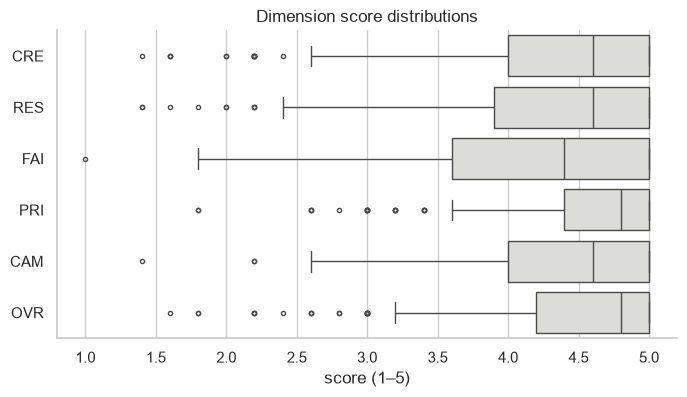

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df[DIMS], orient="h", color="#dddcd8", fliersize=3, ax=ax)
ax.set(xlabel="score (1–5)", title="Dimension score distributions");

## 8. Correlations

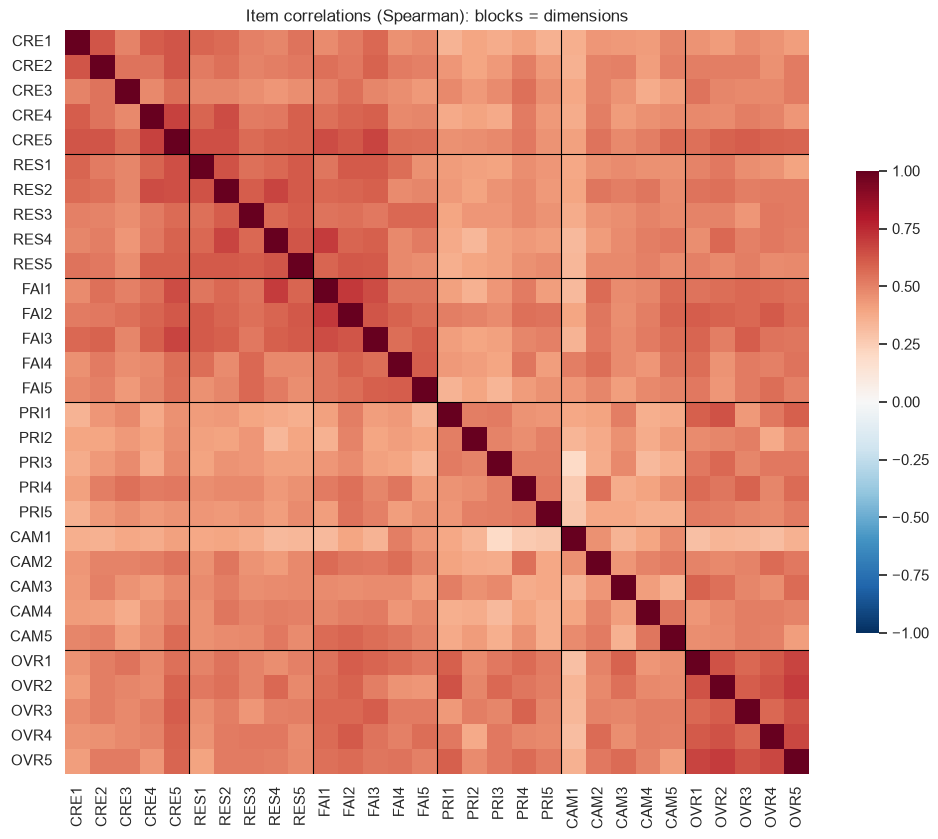

In [30]:
item_corr = df[ITEMS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(item_corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.6})
for b in range(5, 30, 5):
    ax.axhline(b, color="black", lw=0.8); ax.axvline(b, color="black", lw=0.8)
ax.set_title("Item correlations (Spearman): blocks = dimensions");

In [31]:
within = np.mean([item_corr.loc[[f"{d}{i}" for i in range(1, 6)], [f"{d}{i}" for i in range(1, 6)]]
                  .values[np.triu_indices(5, 1)].mean() for d in DIMS])
overall = item_corr.values[np.triu_indices(30, 1)].mean()
round(within, 2), round(overall, 2)

(np.float64(0.56), np.float64(0.49))

Within-block and across-item correlations suggest overlap worth investigating. These averages cannot establish how many factors exist. EFA/CFA is conditional on a measurement question that matters to our conclusions, appropriate treatment of ordinal data, and an adequate validation plan; it is not a required next step.

### Exploratory associations with directly measured outcome items

`OVR1` measures recommendation/advocacy on this survey's 1–5 scale; it is **not eNPS**. `PRI3` measures intention to stay for 3–5 years, not actual retention. `OVR4` measures overall satisfaction. Analyse them separately rather than inventing one engagement outcome. Predictors below exclude all three outcome items.

In [32]:
OUTCOMES = {"OVR1": "recommend", "PRI3": "stay 3–5 yrs", "OVR4": "satisfied"}
drivers = [c for c in ITEMS if c not in OUTCOMES]
out_corr = df[drivers + list(OUTCOMES)].corr(method="spearman").loc[drivers, list(OUTCOMES)]
out_corr.columns = OUTCOMES.values()
out_corr.assign(q=codebook.set_index("col").loc[drivers, "question"].str[:60]).sort_values("stay 3–5 yrs", ascending=False).head(10).round(2)

,recommend,stay 3–5 yrs,satisfied,q
OVR2,0.64,0.57,0.64,"I have opportunities to learn, grow and build my career here"
OVR5,0.68,0.53,0.67,I believe Safewater Lines provides a workplace where I can d
PRI1,0.60,0.52,0.53,I am proud to tell others that I work for Safewater Lines Gr
PRI5,0.52,0.51,0.48,I feel motivated to contribute beyond my basic job responsib
PRI4,0.57,0.51,0.49,I feel that our organization is making a positive impact on
PRI2,0.47,0.50,0.38,I understand how my work contributes to the success of the b
OVR3,0.58,0.49,0.57,I have what I need to perform at my best and contribute to b
CRE5,0.55,0.48,0.59,Leaders are willing to listen to employee feedback and act o
CAM3,0.59,0.48,0.46,I feel that I belong to this organization
FAI2,0.61,0.47,0.62,Employees have equal opportunities to grow and develop their


These are bivariate Spearman associations for exploration, not causal drivers or independent effects. Shared questionnaire context, correlated items, and response styles may influence them. No claim about inflation is established here. Use the pattern and robustness checks to guide further questions; regression is conditional, not automatically required.

## 9. Exploratory segment comparisons

Show group size, mean/median culture summary, and the separate 30-item favourable percentage. Exclude groups below 10 from testing and suppress their scores in the displayed table. The rule is provisional. Approximate rank tests assume independent respondent records; group distributions may differ in shape, so a result is not automatically a median difference. No workforce generalisation is established.

The combined test table below applies **Benjamini–Yekutieli FDR adjustment across all 11 listed exploratory tests**: six full-sample comparisons and five response-style sensitivity comparisons. We use this dependency-tolerant option because the tests overlap. Adjusted p-values do not measure business importance or repair nonresponse bias. See [SciPy FDR documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html) and [Kruskal documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html).

In [33]:
MIN_GROUP_N = 10  # provisional reporting rule, not a universal standard

def seg(col, data=None, score="CULTURE_MEAN"):
    data = df if data is None else data
    g = data.groupby(col, observed=True)
    t = g[score].agg(n="size", mean="mean", median="median")
    t["all_30_fav_pct"] = g["fav_pct"].mean()
    t["small_n"] = t["n"] < MIN_GROUP_N
    t.loc[t["small_n"], ["mean", "median", "all_30_fav_pct"]] = np.nan
    groups = [x[score].dropna().to_numpy() for _, x in g if len(x) >= MIN_GROUP_N]
    p = stats.kruskal(*groups).pvalue if len(groups) > 1 else np.nan
    return t.round(2), p

In [34]:
seg("tenure")[0]

,n,mean,median,all_30_fav_pct,small_n
tenure,,,,,
0 - 3,124,4.30,4.40,83.20,False
3 - 5,53,4.21,4.36,81.45,False
5 - 10,56,4.38,4.54,84.88,False
10 - 15,41,4.70,4.88,95.53,False
15 & Above,53,4.32,4.48,84.28,False


In [35]:
seg("level")[0]

,n,mean,median,all_30_fav_pct,small_n
level,,,,,
0 Unclear,12,4.20,4.16,84.44,False
1 Junior / Support,9,NaN,NaN,NaN,True
2 Executive,131,4.40,4.64,86.01,False
3 Sr Executive,63,4.22,4.28,80.85,False
4 AM / TL,51,4.26,4.28,81.44,False
5 Manager+,51,4.44,4.68,88.24,False
6 Sr Leadership,10,4.49,4.52,90.33,False


In [36]:
seg("region")[0]

,n,mean,median,all_30_fav_pct,small_n
region,,,,,
East,24,4.35,4.46,88.47,False
North,54,4.49,4.72,87.47,False
Overseas,5,NaN,NaN,NaN,True
South,73,4.50,4.68,90.68,False
West,171,4.26,4.40,81.44,False


In [37]:
seg("dept_group")[0]

,n,mean,median,all_30_fav_pct,small_n
dept_group,,,,,
Accounts - Trade,11,4.33,4.32,86.06,False
Customer Service,51,4.09,4.28,75.75,False
Customs Clearance,13,4.45,4.64,88.72,False
Documentation,59,4.41,4.64,85.76,False
Finance & Accounts,38,4.50,4.66,91.05,False
Operations,36,4.61,4.88,93.33,False
Other,65,4.31,4.36,82.72,False
Sales,54,4.31,4.54,84.26,False


In [38]:
seg("gender")[0]

,n,mean,median,all_30_fav_pct,small_n
gender,,,,,
Female,67,4.25,4.32,81.19,False
Male,259,4.39,4.56,86.14,False
Prefer not to tell,1,NaN,NaN,NaN,True


Name supplied versus not supplied is a response-context check, not an identified bias mechanism. The groups may differ in tenure, role or other characteristics. A score difference cannot establish that disclosure caused more positive answers. Never use this variable to identify individuals in a presentation.

In [39]:
test_rows = []
for sample, data, columns in [
    ("all responses", df, ["tenure", "level", "region", "dept_group", "gender", "gave_name"]),
    ("without straight-liners (sensitivity)", df.loc[~df["straightliner"]],
     ["tenure", "level", "region", "dept_group", "gender"]),
]:
    for col in columns:
        table, p = seg(col, data)
        test_rows.append({"sample": sample, "comparison": col,
                          "groups_tested": int((~table["small_n"]).sum()),
                          "respondents_tested": int(table.loc[~table["small_n"], "n"].sum()),
                          "p_unadjusted": p})
segment_tests = pd.DataFrame(test_rows)
segment_tests["p_BY_all_11"] = np.nan
eligible = segment_tests["p_unadjusted"].notna()
segment_tests.loc[eligible, "p_BY_all_11"] = stats.false_discovery_control(
    segment_tests.loc[eligible, "p_unadjusted"], method="by")
display(segment_tests.round(4))

,sample,comparison,groups_tested,respondents_tested,p_unadjusted,p_BY_all_11
0,all responses,tenure,5,327,0.0012,0.0279
1,all responses,level,6,318,0.2375,0.7172
2,all responses,region,4,322,0.0378,0.2509
3,all responses,dept_group,8,327,0.0113,0.0939
4,all responses,gender,2,326,0.0837,0.3475
5,all responses,gave_name,2,327,0.0053,0.0583
6,without straight-liners (sensitivity),tenure,5,273,0.0017,0.0279
7,without straight-liners (sensitivity),level,5,258,0.0613,0.2910
8,without straight-liners (sensitivity),region,4,268,0.0516,0.2858
9,without straight-liners (sensitivity),dept_group,8,273,0.1460,0.4849


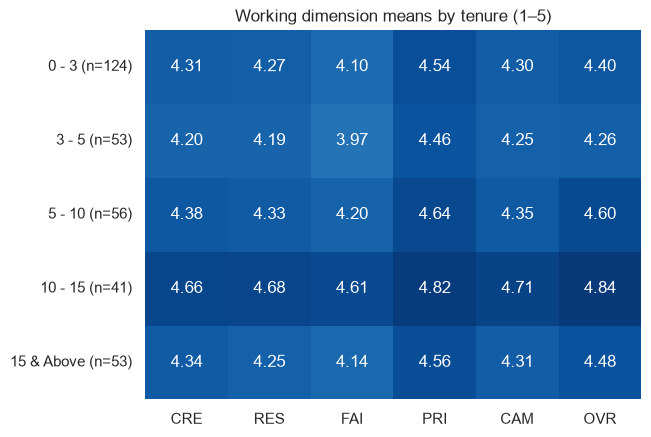

In [40]:
seg_dim = df.groupby("tenure", observed=True)[DIMS].mean()
tenure_n = df.groupby("tenure", observed=True).size().reindex(seg_dim.index)
seg_dim.loc[tenure_n < MIN_GROUP_N] = np.nan
seg_dim.index = [f"{label} (n={n})" for label, n in zip(seg_dim.index, tenure_n)]
sns.heatmap(seg_dim, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=1, vmax=5)
plt.title("Working dimension means by tenure (1–5)");

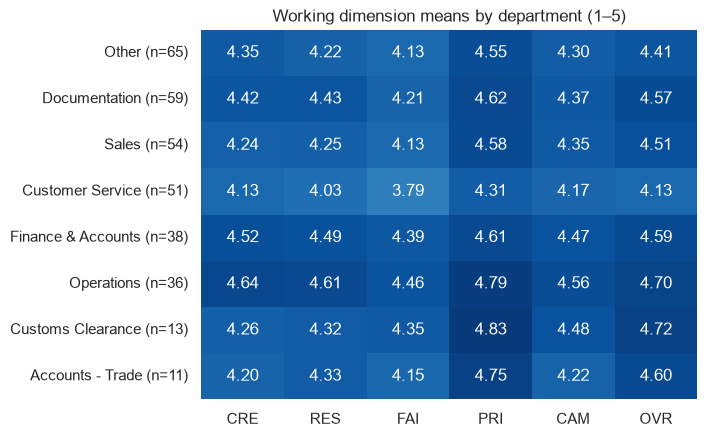

In [41]:
seg_dim = df.groupby("dept_group", observed=True)[DIMS].mean()
dept_n = df.groupby("dept_group", observed=True).size()
seg_dim = seg_dim.loc[dept_n.sort_values(ascending=False).index]
dept_n = dept_n.reindex(seg_dim.index)
seg_dim.loc[dept_n < MIN_GROUP_N] = np.nan
seg_dim.index = [f"{label} (n={n})" for label, n in zip(seg_dim.index, dept_n)]
sns.heatmap(seg_dim, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=1, vmax=5)
plt.title("Working dimension means by department (1–5)");

### Sensitivity: compare with and without straight-liners

The full sample remains the main analysis. Exclusion changes the sample and is not a correction toward a known truth. Inspect changes in size and ranking, not merely whether a p-value crosses a threshold.

In [42]:
pd.DataFrame({
    "all": df[DIMS].mean(),
    "no_straightliners": df.loc[~df["straightliner"], DIMS].mean(),
}).assign(diff=lambda t: t["no_straightliners"] - t["all"]).round(2)

,all,no_straightliners,diff
CRE,4.35,4.24,-0.11
RES,4.32,4.20,-0.12
FAI,4.17,4.02,-0.15
PRI,4.58,4.51,-0.07
CAM,4.35,4.24,-0.11
OVR,4.48,4.39,-0.09


## 10. HR priority (single choice)

In [43]:
theme = pd.read_excel(xl, "Sheet2", header=2).iloc[:10, [0, 2]].set_axis(["option", "theme"], axis=1)
theme["theme"] = theme["theme"].str.strip()
df["hr_theme"] = df["hr_priority"].map(dict(zip(theme["option"], theme["theme"])))
df["hr_theme"].isna().sum()

np.int64(0)

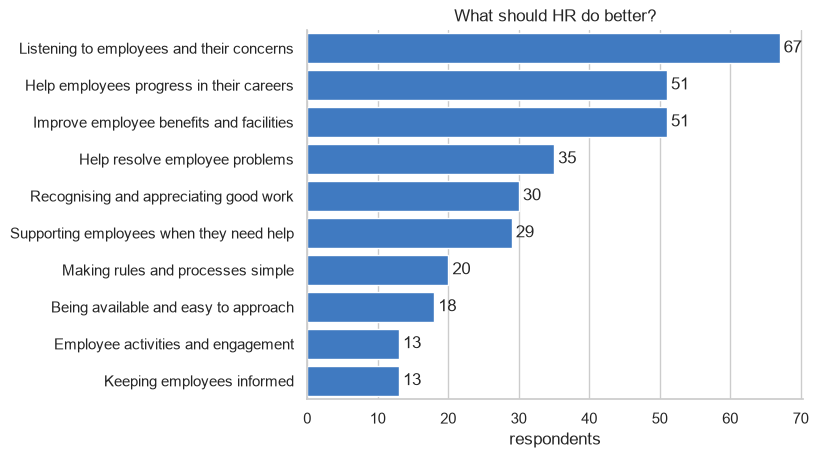

In [44]:
hr = df["hr_priority"].value_counts()
ax = sns.barplot(x=hr.values, y=hr.index, color=BLUE)
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="What should HR do better?", xlabel="respondents", ylabel="");

In [45]:
df["hr_theme"].value_counts(normalize=True).round(3) * 100

hr_theme
Communication            24.5
Grievances               19.6
Development              15.6
Benefits & Facilities    15.6
R&R                       9.2
Process & Policies        6.1
Approachable              5.5
Engagement                4.0
Name: proportion, dtype: float64

In [46]:
def hr_association(col):
    # Descriptive Cramér's V; inspect expected counts before offering an asymptotic p-value.
    counts = df[col].value_counts()
    included = counts[counts >= MIN_GROUP_N].index
    subset = df.loc[df[col].isin(included)]
    ct = pd.crosstab(subset[col], subset["hr_theme"])
    result = stats.chi2_contingency(ct, correction=False)
    denom = ct.to_numpy().sum() * (min(ct.shape) - 1)
    sparse = bool((result.expected_freq < 5).any())
    return {"n_included": len(subset),
            "descriptive_V": np.sqrt(result.statistic / denom) if denom else np.nan,
            "minimum_expected": result.expected_freq.min(),
            "expected_cells_below_5_pct": (result.expected_freq < 5).mean() * 100,
            "asymptotic_p": result.pvalue if not sparse else np.nan,
            "status": "withheld: sparse expected counts" if sparse else "exploratory only"}

hr_associations = pd.DataFrame({c: hr_association(c)
    for c in ["tenure", "level", "region", "dept_group", "gender"]}).T
display(hr_associations)

,n_included,descriptive_V,minimum_expected,expected_cells_below_5_pct,asymptotic_p,status
tenure,327,0.154651,1.629969,40.0,NaN,withheld: sparse expected counts
level,318,0.137937,0.377358,58.333333,NaN,withheld: sparse expected counts
region,322,0.171939,0.968944,40.625,NaN,withheld: sparse expected counts
dept_group,327,0.188263,0.437309,59.375,NaN,withheld: sparse expected counts
gender,326,0.162074,2.671779,18.75,NaN,withheld: sparse expected counts


The single-choice HR question shows the **one selected priority**, not every need an employee has. Cramér's V above is descriptive and can be unstable in sparse tables; no p-values are reported where any expected count is below five. Do not claim a department effect from the original unchecked chi-square calculation. If a decision requires inference, consider a justified permutation approach later. See [SciPy contingency-table guidance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html).

## 11. Open-ended answers: coverage before interpretation

Profile missing and short responses without equating brevity with uselessness. A response such as *nothing* can mean no concern when asked about fairness; *good* may express approval. Flag ambiguous placeholders for contextual review rather than deleting them automatically. No raw comments are displayed here.

In [47]:
txt = df[OE].astype("string").apply(lambda c: c.str.strip().replace("", pd.NA))
PLACEHOLDER = r"^(?:nil|na|n/a|no|none|nothing|ok|okay|yes|good|-|\.|no comments?|nothing to say|all good|no suggestions?)\.?$"
profile = pd.DataFrame({
    "nonblank_n": txt.notna().sum(),
    "blank_%": txt.isna().mean() * 100,
    "context_review_%": txt.apply(
        lambda c: c.str.lower().str.fullmatch(PLACEHOLDER).fillna(False)).mean() * 100,
    "median_words_nonblank": txt.apply(lambda c: c.str.split().str.len()).median(),
})
display(profile.round(1))

,nonblank_n,blank_%,context_review_%,median_words_nonblank
oe_leaders_trust,318,2.8,5.2,8.0
oe_feel_valued,316,3.4,5.5,8.0
oe_fairness_concern,308,5.8,10.1,7.0
oe_value_most,318,2.8,4.6,6.0
oe_teamwork,317,3.1,4.6,7.0
oe_one_change,315,3.7,6.4,8.0


Repeated wording is a review flag, not evidence of machine-generated or dishonest answers. Repeated short answers may be legitimate. Later coding should preserve context, allow multiple codes, document ambiguous cases, and redact identifying details from any presentation excerpts.

In [48]:
pd.DataFrame({
    "nonblank_n": txt.notna().sum(),
    "rows_in_repeated_text_groups": txt.apply(
        lambda c: (c.str.casefold().duplicated(keep=False) & c.notna()).sum()),
})

,nonblank_n,rows_in_repeated_text_groups
oe_leaders_trust,318,33
oe_feel_valued,316,38
oe_fairness_concern,308,47
oe_value_most,318,47
oe_teamwork,317,29
oe_one_change,315,24


## 12. Save processed data

In [49]:
OUT.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT / "survey_clean.csv", index=False)
codebook.to_csv(OUT / "codebook.csv", index=False)
df.shape

(327, 56)

## Summary: exploratory baseline, not the final organisational story

- **327 master responses**, 30 rating items in six supplied blocks, six comment questions and one HR-priority choice. Five demographic fields are retained; the optional name is removed. Workforce response rate is unknown.
- Ratings are mostly positive. Fairness is the lowest-scoring supplied block and Pride the highest; this is an internal comparison, not an external benchmark or certification.
- 54 respondents give the same rating throughout. About 69% supply a name. These are response-context observations; neither proves invalid answers, a halo effect, or the magnitude/direction of bias.
- Existing associations suggest questions about growth, intention to stay, recognition and communication. They do not establish what causes actual retention or engagement.
- Segment patterns are exploratory. Review group sizes and adjusted comparisons before making subgroup claims. Sparse HR-priority tables do not support the previous unchecked chi-square p-values.
- Comments have been profiled, **not yet coded into substantive themes**. Selected HR priorities are not equivalent to comment themes.

**Next: Step 1 below establishes the questions, measures and method choices.** Further analysis will combine item distributions, defensible comparisons and contextual comment coding. Recommendations and the PowerPoint follow the completed evidence review.

# Step 1 — Analytical foundation and method choices

**Status:** foundation and research completed here; substantive comment coding, final priority selection, interventions and PowerPoint remain later stages. All analysis will stay in this notebook.

Our working philosophy is **decision first, evidence before explanation, and employee voice with follow-through**. Preserve strengths as well as address gaps. Prefer the simplest analysis that answers the decision, and state what it cannot establish. CIPD describes people analytics as solving organisational problems with people data and combining it with expertise, research and stakeholder perspectives. [CIPD guide](https://www.cipd.org/uk/knowledge/guides/analytics-practitioner-guide/).

The survey records one-time perceptions. Population size, response rate, workforce composition, survey administration details, earlier results and linked turnover/performance outcomes were not supplied. Describe respondents, use hypotheses for explanations, and make no causal or financial-return claims from these data alone.

## 1.1 What decisions must the analysis support?

These mappings follow question wording; they are **not newly validated scales**. The HR-priority item is separate from comment themes.

| Organisation question | Survey evidence | First analysis | Decision it may inform |
|---|---|---|---|
| What should we preserve? | All 30 item distributions, especially PRI and CAM; `oe_value_most` | Identify consistently positive experiences and read comments for what employees value | Practices to protect while changing other processes |
| Where is leadership trust vulnerable? | CRE1–5; `oe_leaders_trust`; communication-related HR choices | Item distributions and coded accounts of communication, promises and follow-through | Leadership listening and communication practices |
| Where do employees feel insufficiently valued or supported? | RES1–5, OVR3; `oe_feel_valued` | Separate support, resources, recognition and respectful treatment | Manager support, resource provision and recognition |
| Which aspects of fairness need attention? | FAI1–5, relevant comments | Separate rewards, opportunities, decision consistency, workload and explanations | Clarify which policy or decision process to review |
| Where could growth or experience improve? | OVR2, OVR4–5; PRI3; `oe_one_change` | Direct outcomes and exploratory associations, excluding the outcome from its predictors | Career conversations and experience improvements; not individual attrition prediction |
| How well do teams work together? | CAM1–5; `oe_teamwork` | Separate within-team support from cross-team collaboration | Collaboration and handover practices |
| Whose experience differs? | Tenure, department, region, gender; approximate role groups | Group sizes, distributions and differences, with response-style sensitivity | Targeted follow-up after checking context and possible confounding |
| What should HR do first? | Single-choice `hr_priority`, coded comments, rating gaps | Triangulate employee-selected priorities with recurring concerns and relative strengths | A short, justified intervention list with proposed owners and success measures |

## 1.2 Establish the base before interpreting scores

The table below verifies the analytical unit and coverage using the actual in-memory data. An employee record is the unit for respondent comparisons. Item responses are the unit for pooled answer percentages; 30 answers from one employee are not 30 independent employees.

In [50]:
assert len(ITEMS) == 30 and len(set(ITEMS)) == 30
assert len(raw) == len(df) and raw.index.equals(df.index)
assert df[ITEMS].isin([1, 2, 3, 4, 5]).all().all(), "Review missing/unmapped ratings"
assert "full_name" not in df.columns
assert item_counts.sum(axis=1).eq(valid_n).all()
assert np.allclose(item_stats[["fav_%", "sometimes_%", "unfav_%"]].sum(axis=1), 100)
assert df["hr_theme"].notna().all(), "Review unmapped HR-priority options"

base_register = pd.DataFrame([
    ("Unit of analysis", "One master response record; unique employee identity is not verified"),
    ("Master response records", len(df)),
    ("Rating items / supplied blocks", f"{len(ITEMS)} / {len(DIMS)}"),
    ("Valid rating answers", int(valid_n.sum())),
    ("Valid answers per rating item", f"{int(valid_n.min())}–{int(valid_n.max())}"),
    ("Missing rating answers", int(df[ITEMS].isna().sum().sum())),
    ("Identical-category response records", int(df["straightliner"].sum())),
    ("Nonblank answers across six comment questions", int(txt.notna().sum().sum())),
    ("Comment contributors (at least one nonblank answer)", int(txt.notna().any(axis=1).sum())),
    ("Valid single-choice HR-priority records", int(df["hr_priority"].notna().sum())),
    ("Eligible workforce / response rate", "Not provided / not calculable"),
    ("External benchmark / previous wave", "Not provided / not provided"),
], columns=["Base parameter", "Observed value or limitation"])
display(base_register)

,Base parameter,Observed value or limitation
0,Unit of analysis,One master response record; unique employee identity is not verified
1,Master response records,327
2,Rating items / supplied blocks,30 / 6
3,Valid rating answers,9810
4,Valid answers per rating item,327–327
5,Missing rating answers,0
6,Identical-category response records,54
7,Nonblank answers across six comment questions,1892
8,Comment contributors (at least one nonblank answer),321
9,Valid single-choice HR-priority records,327


## 1.3 Measurement contract

| Measure | Definition / denominator | Interpretation rule |
|---|---|---|
| Item response distribution | Count in each of 1–5 divided by valid responses to that item | Primary evidence; category 3 is Sometimes, not neutral |
| Favourable % | Count of 4–5 / valid item responses ×100 | Convenient summary; always retain lower categories and top-box |
| Unfavourable % / top-box % | Count of 1–2 / valid n; count of 5 / valid n | Distinguish reported problems from intensity of positive answers |
| Working item/block mean | Equal-spaced 1–5 coding; block is an equal-weight five-item mean | Transparent approximation, not proof of interval measurement or a validated construct |
| Culture summary | Equal-weight 25-item mean, excluding OVR | Optional descriptive overview; avoid part–whole outcome correlations |
| Advocacy / intention to stay / satisfaction | OVR1 / PRI3 / OVR4, each kept separate | Direct survey perceptions, not eNPS, actual turnover or observed performance |
| Segment difference | Show group n and differences on the same measure | Report percentage points for percentage differences; no unsupported population extrapolation |
| Selected HR priority | Option count / valid answers to the single-choice item | One selected priority, not prevalence of every concern |
| Comment-topic prevalence — planned | Unique contributors mentioning topic / explicitly stated contributor base | Multi-label totals can exceed 100%; count people once per topic across questions if using a person-level base |
| Response-style sensitivity | Full-sample result versus a clearly labelled alternative sample | Excluding straight-liners is not assumed to recover the truth |

Our display convention follows the practical use of distributions and positive-response shares in employee surveys, while keeping the full scale visible. The Civil Service methodology illustrates why a mean-based index and a favourable percentage carry different information; its questionnaire, index and benchmarks are **not transferred** to Safewater Lines. [Civil Service methodology](https://www.gov.uk/government/publications/civil-service-people-survey-2025-results/quality-and-methodology-information-for-the-civil-service-people-survey-2025).

## 1.4 Research: what fits this project?

Sources consulted 28 October 2026. The decisions below are our assessment of fit, not endorsements of this dataset by the authors.

| Source / perspective | Useful lesson | Our decision |
|---|---|---|
| [CIPD: people analytics](https://www.cipd.org/uk/knowledge/guides/analytics-practitioner-guide/) | Connect the investigation to a decision and combine several forms of evidence | Adopt a question-to-action structure; seek business context before final recommendations |
| [Civil Service survey methodology](https://www.gov.uk/government/publications/civil-service-people-survey-2025-results/quality-and-methodology-information-for-the-civil-service-people-survey-2025) | A positive-response share can hide different full-scale patterns | Adopt distributions plus favourable %, with clear denominators; do not borrow its engagement index or benchmark |
| [ASA statement](https://doi.org/10.1080/00031305.2016.1154108) | Statistical evidence needs context; a threshold does not establish importance | Report observed differences, sample context and limitations; keep tests exploratory |
| [SciPy: contingency tables](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html) | Sparse expected frequencies undermine a routine asymptotic chi-square interpretation | Audit the table before inference; current sparse-table p-values are withheld |
| [Braun & Clarke: types of thematic analysis](https://www.thematicanalysis.net/understanding-ta/) and [review guidance](https://www.thematicanalysis.net/editor-checklist/) | Codebook, coding-reliability and reflexive approaches are different methodological choices | Plan a practical codebook-based content analysis for short survey comments; do not claim reflexive TA while imposing fixed codes and inter-rater reliability |
| [r/IOPsychology practitioner discussion](https://www.reddit.com/r/IOPsychology/comments/1rj1df7/need_help_conducting_my_first_employee_survey/) | Participants emphasise clear survey purposes, understandable summaries, confidentiality and meaningful follow-up | Treat this as practical experience, not validation. Do not adopt forum claims that measurement validity is unimportant |
| [Zadeh: fuzzy sets](https://doi.org/10.1016/S0019-9958(65)90241-X) | Fuzzy membership represents degrees of belonging to a defined set | Consider only with an explicit decision meaning, calibrated membership functions and sensitivity checks |
| [Di Nardo & Simone: model-based fuzzy questionnaires](https://arxiv.org/abs/1912.09883) | A fuzzy questionnaire method can incorporate a statistical model rather than merely replace category labels | Keep as a research candidate; its different application does not validate our membership choices or prove improvement here |

**Coherent quantitative approach:** use distributions as primary evidence; working means as clearly labelled summaries; rank associations and group tests only for relevant exploratory questions. This is not a blanket claim that all parametric methods are invalid for Likert data. More complex models need a clear incremental question and checks, rather than being added for appearance.

**Coherent qualitative approach — planned:** read answers in question context → draft code definitions with inclusion/exclusion examples → pilot and revise → record each coding decision and ambiguous case → review a shared subset → count unique contributors at the chosen denominator → interpret with representative, redacted excerpts. Distinguish genuine no-concern answers from missing/unclear text. Keyword matching may assist retrieval but will not be treated as completed coding or validated sentiment.

## 1.5 Fuzzy analysis: establish the added value first

Fuzzy logic allows partial membership in a concept such as “high satisfaction”; membership is not automatically a probability, a statistical confidence level, or the employee's self-reported uncertainty. Distinguish fuzzy comprehensive evaluation (FCE), fuzzy clustering and fuzzy-set QCA: they answer different questions. We have not selected any of them solely because survey opinions are subjective. [Zadeh](https://doi.org/10.1016/S0019-9958(65)90241-X).

**A useful baseline check, derived here:** let `P[j,k]` be the observed share selecting category `k` on item `j`. In a frequency-based weighted-average evaluation, using equal item weights and category scores 1–5 gives `mean_j(P[j,:]) @ [1,2,3,4,5]`. With complete data this is exactly the pooled ordinary mean. Calling that calculation fuzzy would add no information.

The check below evaluates this specific construction on our data. It does **not** implement or reject all fuzzy methods, and the response-frequency matrix is not independently elicited fuzzy membership.

In [51]:
frequency_profiles = item_counts.div(valid_n, axis=0)
category_values = np.arange(1, 6, dtype=float)
fuzzy_baseline_rows = []
for block in DIMS:
    block_items = [f"{block}{i}" for i in range(1, 6)]
    ordinary_mean = df[block_items].to_numpy(dtype=float).mean()
    frequency_evaluation = frequency_profiles.loc[block_items].mean(axis=0).to_numpy() @ category_values
    fuzzy_baseline_rows.append((block, ordinary_mean, frequency_evaluation,
                                abs(ordinary_mean - frequency_evaluation)))
fuzzy_baseline_check = pd.DataFrame(fuzzy_baseline_rows, columns=[
    "block", "ordinary_mean", "equal_weight_frequency_evaluation", "absolute_difference"])
assert np.allclose(fuzzy_baseline_check["absolute_difference"], 0, atol=1e-12)
display(fuzzy_baseline_check.round(6))

,block,ordinary_mean,equal_weight_frequency_evaluation,absolute_difference
0,CRE,4.352294,4.352294,0.0
1,RES,4.316820,4.316820,0.0
2,FAI,4.167584,4.167584,0.0
3,PRI,4.581651,4.581651,0.0
4,CAM,4.352905,4.352905,0.0
5,OVR,4.481957,4.481957,0.0


**Decision:** do not add this equivalent frequency-weighted score to the executive findings. A substantive fuzzy extension remains **conditional**, not completed. To adopt one, specify its organisational decision, justify membership anchors/weights using theory or stakeholder elicitation, compare it with the simple baseline, and test whether conclusions change across plausible calibrations. If rankings change, explain which assumption changes them; a different ranking is not evidence of greater accuracy. We currently lack elicited memberships, decision weights and an independent validation outcome.

If later we use a fuzzy model, show its incremental value and limitations in the methodology table. Fuzzy membership alone cannot recover missing workforce data, establish causality or predict actual turnover from intention-to-stay answers. Statistical fuzzy questionnaire models exist, but their calibration and fit must be examined before transferring them here. [Di Nardo & Simone](https://arxiv.org/abs/1912.09883).

## 1.6 HR concepts that help interpret the evidence

These are interpretive lenses, not extra measured variables or diagnoses.

| Concept | Meaning for our questions | Appropriate use / limit |
|---|---|---|
| Employee experience | Employees' experiences of work, support, relationships and organisational processes | Use exact items and comments; do not reduce every experience to one average |
| Engagement, satisfaction and commitment | Related concepts with different meanings | Keep measured satisfaction, advocacy, belonging and intention to stay visible rather than calling all of them one validated engagement score. [CIPD evidence review](https://www.cipd.org/en/knowledge/evidence-reviews/evidence-engagement/) |
| Organisational justice | Fairness of outcomes, procedures, interpersonal treatment and information | A useful reading lens for FAI1/4 (outcomes), FAI3 (procedures), RES5 (treatment), FAI5 (explanations); these items are not Colquitt's validated subscales. [Colquitt, 2001](https://pubmed.ncbi.nlm.nih.gov/11419799/) |
| Psychological safety | A shared team belief about interpersonal risk-taking | RES3 is relevant to speaking up, but one item does not establish Edmondson's full construct or a team-level score. [Edmondson, 1999](https://dash.harvard.edu/entities/publication/13a7b031-0fdd-45ec-a7e0-2b80e2bc679f) |
| Employee voice and closing the loop | Asking, listening, responding and showing what happens next | Treat CRE5 and comments as evidence for follow-up; measure both whether leaders act and whether employees experience improvement |
| Perceived organisational strengths | Experiences employees rate positively and say they value | Preserve them alongside improvements; a rare serious concern still deserves contextual review |
| Evidence-based HR | Combine organisational data, research, professional expertise and stakeholder views | Use our survey as one input, not as the complete business case. [CIPD guide](https://www.cipd.org/uk/knowledge/guides/analytics-practitioner-guide/) |
| Theory of change | An explicit proposal linking action to an expected mechanism and outcome | Explain why an intervention may help, then evaluate it; this is a planning hypothesis, not an observed survey result |

Advocacy remains OVR1 on a five-point frequency scale. Standard NPS uses a zero-to-ten recommendation protocol; no mechanical rescaling makes our item standard eNPS. [Bain scoring protocol](https://www.netpromotersystem.com/about/measuring-your-net-promoter-score/).

## 1.7 What follows Step 1?

1. **Review the evidence from the base:** item distributions, denominator-aware strength/gap profiles, and selected HR priorities. Avoid duplicating the EDA.
2. **Examine relevant variation:** group sizes, meaningful differences and stability; contextualise approximate job levels and mixed Other groups. Do not predetermine which demographic group must be a problem.
3. **Code the six comment questions:** preserve strengths, concerns, suggestions and explicit no-concern responses. Integrate topics with rating patterns and investigate contradictions.
4. **Consider conditional extensions:** association modelling, factor analysis or calibrated fuzzy analysis only where they answer an unresolved decision better than the baseline.
5. **Build the organisational story and roadmap:** observation → supported interpretation → proposed action → accountable owner → baseline/success measure → review point. Prioritise using reach, severity, evidence and feasibility, with explicit trade-offs rather than invented weights.
6. **Prepare the executive PowerPoint last:** strengths, priority opportunities, who is affected, employee voice, proposed interventions, roadmap and success measures. Use reviewed aggregate visuals and redacted excerpts.

Step 1 does not establish comment themes, causal drivers, a final priority ranking, intervention effects or PPT conclusions. The methodology reference at the end records what is actually used versus planned or conditional.

---
# Annexure

## A. Essential terms and interpretation

| Term | Meaning and use in this project |
|---|---|
| CRE / RES / FAI / PRI / CAM / OVR | Credibility / Respect / Fairness / Pride / Camaraderie / Overall Employee Experience; supplied question blocks |
| OE / HR | Open-ended response / Human Resources |
| AM / TL / R&R | Assistant Manager / Team Leader / Rewards and Recognition |
| Culture summary | Our descriptive 25-item mean; not a validated or official culture summary |
| Favourable / unfavourable | Scores 4–5 / 1–2; show the valid-answer denominator and retain Sometimes separately |
| Percentage points | Subtract percentages directly; 80% to 85% is +5 percentage points |
| Reliability / validity | Consistency of a measure / evidence supporting an interpretation and intended use; one does not prove the other |
| Alpha | Internal consistency statistic under assumptions; not a universal pass/fail test or proof of one factor |
| Spearman rho | Rank association; no causal or independent-effect interpretation |
| p-value | Under the specified null model and assumptions, probability of a test statistic at least as extreme as observed; not the probability the null is true or that chance caused the result |
| BY-adjusted p-value | Adjustment controlling false discovery rate under general dependence, when the input tests are valid |
| Kruskal–Wallis | Independent-group rank comparison; does not identify which groups differ; median interpretation needs appropriate distributional assumptions |
| Cramér's V | Descriptive categorical association; sparse tables and sample size affect interpretation |
| Ceiling effect / straight-lining | Concentration at the top category / one category used throughout; do not automatically discard responses |
| eNPS | A recommendation measure using an NPS scoring protocol; not computable from our 1–5 OVR1 item as standard eNPS |

Definitions and methodological decisions are expanded in Step 1; linked research sources and the final methodology table provide references.

## B. Variables created in this notebook (`data/processed/survey_clean.csv`)

| Column | Type | Definition |
|---|---|---|
| `CRE1` … `OVR5` | int 1–5 | Likert answers converted to numbers (see C.1) |
| `CRE`, `RES`, `FAI`, `PRI`, `CAM`, `OVR` | float 1–5 | Dimension scores: mean of 5 items |
| `CULTURE_MEAN` | float 1–5 | Mean of 25 items (all dimensions except OVR) |
| `fav_pct` | float 0–100 | Respondent's % of the 30 answers that are 4 or 5 |
| `level` | category | Designation grouped into 7 levels (see C.2) |
| `region` | category | City grouped into 5 regions (see C.3) |
| `dept_group` | category | Department, with those under 10 respondents merged into *Other* |
| `hr_theme` | category | HR-priority option grouped into 8 themes (see C.4) |
| `straightliner` | bool | Same answer to all 30 items |
| `gave_name` | bool | Filled in the optional name field (the name itself is dropped) |

Actual names are excluded from `survey_clean.csv`. The codebook retains the optional field definition, never name values.

## C. Mappings used

**C.1 Likert scale**

| Raw label(s) | Score |
|---|---|
| Almost never · Almost Never | 1 |
| Rarely | 2 |
| Sometimes | 3 |
| Usually · Often (Hindi form) | 4 |
| Almost always · Almost Always · Always (Malayalam form) | 5 |

**C.2 Level** (keyword rules, checked in this order)

| Level | Designations containing |
|---|---|
| 6 Sr Leadership | chief, general manager, head of |
| 4 AM / TL | assistant manager, team leader, supervisor |
| 5 Manager+ | manager (Manager, Sr/Deputy/Branch/Area/Project Manager…) |
| 3 Sr Executive | senior executive |
| 2 Executive | executive |
| 1 Junior / Support | junior, assistant, runner, off role |
| 0 Unclear | anything else (e.g. *SALES*, *IMPORT*, *Branch Accountant*, *Do not want to disclose*) |

**C.3 Region**

| Region | Locations |
|---|---|
| West | Mumbai, Nhava Sheva, Pune, Ahmedabad, Gandhidham, Baroda, Mundra, Aurangabad |
| North | Noida, Kanpur, Ludhiana, Jaipur, Panipat |
| South | Cochin, Chennai, Hyderabad, Bangalore, Coimbatore, Vizag, Tuticorin |
| East | Kolkata |
| Overseas | Nairobi, New Jersey |

**C.4 HR theme** (from the workbook's `Sheet2`)

| Theme | HR-priority options |
|---|---|
| Communication | Listening to employees and their concerns · Keeping employees informed |
| Grievances | Help resolve employee problems · Supporting employees when they need help |
| Development | Help employees progress in their careers |
| Benefits & Facilities | Improve employee benefits and facilities |
| R&R | Recognising and appreciating good work |
| Process & Policies | Making rules and processes simple |
| Approachable | Being available and easy to approach |
| Engagement | Employee activities and engagement |

## D. Data lineage and reproducibility

| Item | Detail |
|---|---|
| Source | `data/raw/Your Voice- Responses 21 OCT - FINAL.xlsx`; keep unchanged |
| Analysis sheet | `SWL - MASTERDATA`: 327 responses, 43 source columns, two header rows |
| Source discrepancy | Language exports total 330; master has 327. A verified row-level reconciliation is not available |
| Transformations | Harmonise response labels, repair designation header, remove name, create documented reporting groups and working scores |
| Grouping limits | Job levels are keyword approximations; Other departments are heterogeneous; no weighting to workforce composition |
| Outputs | `survey_clean.csv` and `codebook.csv`; regenerate by running top to bottom |
| Schema change | `TRUST_INDEX` renamed `CULTURE_MEAN` to identify an analyst-created descriptive measure |
| Environment | Project `.venv`, dependencies pinned by `uv.lock`; all analysis remains in this notebook |

The option mappings above document transformations; the live codebook in §2 contains all source questions. Do not infer survey collection procedures or removal reasons from row counts alone.

# Methodology reference — maintained as the last Markdown cell

Status as of **28 October 2026**. “Used” means executed in this notebook; “planned” means specified but not performed. All results describe responding records unless stated otherwise. Research links support the method's meaning, not the validity of our particular survey.

| Method / measure | Organisational purpose | Inputs / assumptions | Decision and current status | Limits / reference |
|---|---|---|---|---|
| Source and quality audit | Establish a trustworthy base | Master sheet, headers, missingness, label mapping, row counts | **Used**; raw preserved; names removed; row-count discrepancy documented | Unique employee identity, sampling frame and removal log not verified |
| Item distributions and favourable % | Identify strengths and improvement opportunities | Valid n per item; categories 1–5; favourable=4–5, unfavourable=1–2 | **Used, primary descriptive evidence** | Sometimes is not neutral; no borrowed external thresholds. [Civil Service example](https://www.gov.uk/government/publications/civil-service-people-survey-2025-results/quality-and-methodology-information-for-the-civil-service-people-survey-2025) |
| Item/block means and culture summary | Provide a compact overview beside distributions | Equal category spacing, equal weights; culture summary uses 25 items | **Used as descriptive working measures**, not validated or branded indices | Do not correlate a composite with its own included outcome as driver evidence |
| Cronbach alpha and corrected item–total correlations | Inspect coherence of supplied blocks | Covariation of items; interpret alpha under its assumptions | **Used as diagnostics**; no automatic item deletion | Does not establish dimensionality or validity; EFA/CFA remains conditional |
| Spearman correlations | Explore relationships with advocacy, intention to stay and satisfaction | Independent respondent records; ordinal ranking; outcomes excluded from predictor list | **Used, exploratory**; no significance-based item screening | Associations do not establish causality or independent effects |
| Group descriptions and provisional n≥10 reporting rule | Understand variations relevant to follow-up | Tenure, department, region, gender, approximate levels | **Used**; show n; suppress small-group scores in comparison tables | Threshold is a project rule, not a proof of privacy or adequate precision |
| Kruskal–Wallis plus BY FDR adjustment | Assess exploratory differences across eligible groups | Independent records; adequate group sizes; 11 overlapping full/sensitivity tests | **Used**, joint family of 11 tests; retain effect size/context in interpretation | Omnibus result does not identify pairs or prove a median shift. [Kruskal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html), [BY](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html) |
| Response-style sensitivity | Check dependence on identical-category respondents | Keep full sample primary; compare a labelled alternative | **Used** for scores and exploratory tests | Exclusion is not assumed to improve validity |
| HR-priority counts and descriptive Cramér's V | Understand the one HR priority selected | Recompute from master; inspect expected cell counts and group sizes | **Used descriptively**; sparse-table asymptotic p-values withheld | V may be unstable; permutation inference conditional on decision need. [SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html) |
| Comment coverage and repeated-text flags | Establish usable qualitative material | Six questions, nonblank answers, context-review flags | **Used as profiling only** | Short or repeated answers are not automatically invalid |
| Codebook-based qualitative content analysis | Explain employee concerns, strengths and suggestions | Contextual reading, code definitions, pilot/revision, multi-label records, review trail | **Planned**, not yet coded; contributor denominator must be stated | Avoid equating word counts or automatic sentiment with reviewed themes; distinct from reflexive TA. [Method distinctions](https://www.thematicanalysis.net/understanding-ta/), [review guidance](https://www.thematicanalysis.net/editor-checklist/) |
| Quantitative–qualitative integration | Build an evidence-backed organisational story | Rating patterns, reviewed coded comments, HR choices; show disagreements | **Planned** | Convergence strengthens interpretation but does not establish causality |
| Equal-weight frequency evaluation equivalence check | Test whether a proposed fuzzy-style calculation adds information | Complete responses, empirical category shares, equal item weights, scores 1–5 | **Used as an algebra/data check**; exactly equals the ordinary mean, so omit as a separate insight | Specific construction, not a validation or rejection of all fuzzy approaches |
| Calibrated fuzzy analysis | Potentially represent graded decision concepts | Explicit memberships, anchors, weights, validation and sensitivity | **Conditional; not implemented**; no calibrated inputs supplied | Membership is not probability; adopt only with decision value beyond baseline. [Zadeh](https://doi.org/10.1016/S0019-9958(65)90241-X), [questionnaire model](https://arxiv.org/abs/1912.09883) |
| EFA/CFA or multivariable ordinal models | Resolve a necessary measurement or association question | Ordinal-aware specification, identifiability, fit, sample/ceiling checks and validation | **Conditional; not implemented** | No automatic EFA→CFA validation on the same sample; predictive validation is not causal identification |
| Prioritisation, action roadmap and evaluation | Translate evidence into measurable interventions | Reach, severity, evidence, feasibility, proposed owners, baseline and review measures | **Planned**, followed by the final executive PowerPoint | No invented ROI, causal effects or success targets. [CIPD](https://www.cipd.org/uk/knowledge/guides/analytics-practitioner-guide/) |

**Not selected:** standard eNPS from the five-point item; an official Trust Index label for our custom mean; automatic causal “driver” claims; uncalibrated fuzzy rankings; generic word clouds as qualitative findings; unchecked sparse-table inference; individual attrition predictions without observed outcomes. [NPS protocol](https://www.netpromotersystem.com/about/measuring-your-net-promoter-score/).